<a href="https://colab.research.google.com/github/IgnacioAntonio82/AprendizajeAutomatico2/blob/main/TrabajoPractico2AA2/TP2_AA2_Aguilar_Ignacio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Replica el código del tutorial A - Clasificacion de audio

In [30]:
import torch # PyTorch: biblioteca principal para trabajar con tensores y redes neuronales.
import torch.nn as nn # nn contiene las capas y clases necesarias para construir la red neuronal.
import torch.nn.functional as F # functional proporciona funciones como ReLU y log_softmax.
import torch.optim as optim # optim contiene los optimizadores que actualizan los pesos de la red.
from torchvision import datasets, transforms
# Dataset permite crear una clase personalizada para cargar los audios
# y asociar cada archivo con su etiqueta.
from torch.utils.data import Dataset
import torchaudio # TorchAudio permite cargar y procesar archivos de audio.
# Pandas permite leer el archivo CSV con los nombres y las etiquetas
# de los audios de UrbanSound8K.
import pandas as pd
# NumPy proporciona herramientas para operaciones numéricas con arrays.
import numpy as np
# OS permite trabajar con archivos y directorios del sistema.
import os
# IPython.display permite reproducir audios dentro de Google Colab.
import IPython.display as ipd
from IPython.display import display


# Permite mostrar y reproducir contenido multimedia, como audio,
# directamente dentro de un notebook de Jupyter o Google Colab.
import IPython
# Permite crear gráficos y visualizar datos, señales de audio,
# espectrogramas y otros resultados del procesamiento.
import matplotlib.pyplot as plt
# Importa una función auxiliar de torchaudio para descargar
# archivos de recursos utilizados en ejemplos y tutoriales.
from torchaudio.utils import _download_asset



In [31]:
#Ese código sirve para seleccionar automáticamente si PyTorch va a utilizar la GPU o la CPU para ejecutar la red neuronal.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


Utilizaremos el conjunto de datos UrbanSound8K para entrenar nuestra red neuronal. Está disponible de forma gratuita en https://urbansounddataset.weebly.com/?utm_source=chatgpt.com  y contiene 10 clases de audio con más de 8000 muestras de sonido.

Una vez que hayas descargado el conjunto de datos comprimido, descomprimilo en tu directorio de trabajo actual.

Primero, examinaremos el archivo CSV, que proporciona información sobre cada uno de los archivos de sonido individuales. La biblioteca pandas nos permite abrir el archivo CSV y utilizar .iloc[] para acceder a los datos que contiene.

In [32]:
# Descarga el archivo comprimido UrbanSound8K.tar.gz desde Zenodo.
# !wget ejecuta el comando de descarga en Google Colab.
!wget -c -O UrbanSound8K.tar.gz "https://zenodo.org/records/1203745/files/UrbanSound8K.tar.gz?download=1"

--2026-10-31 23:16:01--  https://zenodo.org/records/1203745/files/UrbanSound8K.tar.gz?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.51.60, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 416 REQUESTED_RANGE_NOT_SATISFIABLE

    The file is already fully retrieved; nothing to do.



In [33]:
#Descomprimí el archivo
!tar -xzf UrbanSound8K.tar.gz
#Esto creará la carpeta UrbanSound8K, que contiene metadata y audio.

In [34]:
#Este código sirve para cargar el archivo CSV del conjunto de datos UrbanSound8K y mostrar la primera fila con toda su información.
csvData = pd.read_csv('./UrbanSound8K/metadata/UrbanSound8K.csv')
# Muestra todas las columnas de la primera fila de la tabla.
print(csvData.iloc[0, :])

slice_file_name    100032-3-0-0.wav
fsID                         100032
start                           0.0
end                        0.317551
salience                          1
fold                              5
classID                           3
class                      dog_bark
Name: 0, dtype: object


Las 10 clases de audio del conjunto de datos UrbanSound8K son: aire acondicionado (air_conditioner), bocina de automóvil (car_horn), niños jugando (children_playing), ladrido de perro (dog_bark), perforación (drilling), motor en ralentí (engine_idling), disparo de arma (gun_shot), martillo neumático (jackhammer), sirena (siren) y música callejera (street_music).

El primer archivo contiene música callejera y el segundo, el sonido de un aire acondicionado.

In [35]:
#Este código sirve para cargar y reproducir dos archivos de audio del conjunto de datos UrbanSound8K, para que puedas escuchar cómo suenan las distintas clases de sonidos.

ipd.Audio('./UrbanSound8K/audio/fold1/108041-9-0-5.wav')

ipd.Audio('./UrbanSound8K/audio/fold5/100852-0-0-19.wav')

In [36]:
#¿Cómo escuchar los audios?
# Primer audio: música callejera
display(ipd.Audio('./UrbanSound8K/audio/fold1/108041-9-0-5.wav'))

# Segundo audio: aire acondicionado
display(ipd.Audio('./UrbanSound8K/audio/fold5/100852-0-0-19.wav'))

#Preparación y formato de los datos
Ahora que conocemos el formato de las entradas del archivo CSV, podemos construir nuestro conjunto de datos.

Crearemos una clase envoltorio (wrapper) para nuestro conjunto de datos utilizando torch.utils.data.Dataset, que se encargará de cargar los archivos y realizar algunos pasos de preparación y formato.

El conjunto de datos UrbanSound8K está dividido en 10 carpetas. Utilizaremos los datos de 9 de estas carpetas para entrenar nuestra red neuronal y luego usaremos la décima carpeta para probarla.

Cuando se inicialice, la clase envoltorio almacenará los nombres de los archivos, las etiquetas y los números de las carpetas de los archivos de audio que se encuentren en la lista de carpetas proporcionada como entrada.

Los pasos de carga y preparación propiamente dichos se realizarán en la función de acceso __getitem__.

Dentro de __getitem__, utilizamos torchaudio.load() para convertir los archivos WAV en tensores. torchaudio.load() devuelve una tupla que contiene el tensor recién creado junto con la frecuencia de muestreo del archivo de audio (44,1 kHz en el caso de UrbanSound8K).

El conjunto de datos utiliza dos canales de audio, por lo que utilizaremos torchaudio.transforms.DownmixMono() para convertir los datos de audio a un solo canal.

A continuación, necesitamos dar formato a los datos de audio. La red neuronal que construiremos acepta una entrada de tamaño 32.000, mientras que la mayoría de los archivos de audio tienen bastante más de 100.000 muestras.

El audio de UrbanSound8K se muestrea a 44,1 kHz, por lo que 32.000 muestras abarcan solamente unos 700 milisegundos. Al reducir la frecuencia de muestreo del audio a aproximadamente 8 kHz, podemos representar 4 segundos utilizando las 32.000 muestras.

Esta reducción de la frecuencia de muestreo se consigue tomando una de cada cinco muestras del tensor de audio original.

No todos los tensores de audio tienen una longitud suficiente para realizar esta reducción y alcanzar el tamaño necesario. Por lo tanto, será necesario completar esos tensores con ceros (zero-padding).

La longitud mínima que permite evitar el relleno con ceros es de 160.000 muestras


#Conversión del audio a mono

En el código original del tutorial se utiliza torchaudio.transforms.DownmixMono() para convertir el audio a un solo canal. Un archivo de audio puede tener dos canales (estéreo), mientras que para este ejercicio queremos trabajar con una única señal (mono).

Sin embargo, la versión de TorchAudio instalada en Google Colab no dispone de la función DownmixMono(), por lo que su utilización genera un error de tipo AttributeError.

Para solucionar este problema, reemplazamos esa transformación por una operación que promedia los canales del audio. De esta manera, mantenemos la finalidad del código original y adaptamos la implementación a la versión actual de la biblioteca.

In [37]:
class UrbanSoundDataset(Dataset):
    """
   En esta parte del trabajo creo una clase llamada UrbanSoundDataset, que hereda de Dataset de PyTorch.
   El objetivo de esta clase es cargar los audios de UrbanSound8K, prepararlos para que tengan un formato uniforme y asociar cada audio con su etiqueta correspondiente.
   Después, voy a utilizar un DataLoader para entregar estos audios a la red neuronal en lotes.
    """

    def __init__(self, csv_path, file_path, folderList):
        """
        El método __init__ se ejecuta cuando creo un objeto de la clase.
        Recibe tres parámetros: la ruta del archivo CSV, la ruta de los audios y la lista de carpetas que quiero seleccionar.
        Primero leo el archivo CSV con Pandas. Después creo tres listas: una para los nombres de los archivos, otra para las etiquetas y otra para los números de carpeta.
        Con un bucle for recorro todas las filas del CSV. La condición if comprueba si el audio pertenece a una de las carpetas seleccionadas.
        Si cumple la condición, guardo su nombre, su etiqueta y su carpeta utilizando append().
        Finalmente, guardo la ruta base de los audios para poder encontrarlos más adelante.

        """
        # Leemos el archivo CSV que contiene los nombres de los audios,
        # sus etiquetas y el número de carpeta al que pertenecen.
        csvData = pd.read_csv(csv_path)
        # Creamos listas para almacenar los nombres de archivo,
        # las etiquetas y las carpetas seleccionadas.
        self.file_names = []
        self.labels = []
        self.folders = []

        #El bucle for recorre los registros del CSV, el if filtra las carpetas seleccionadas y append() agrega a las listas los nombres, las etiquetas y las carpetas de
        #los audios que cumplen la condición.
        for i in range(0,len(csvData)): #Recorrer todas las filas
            if csvData.iloc[i, 5] in folderList:
                self.file_names.append(csvData.iloc[i, 0]) #guardar el nombre del audio
                self.labels.append(csvData.iloc[i, 6]) #Guardar la etiqueta del audio
                self.folders.append(csvData.iloc[i, 5]) #Guardar el número de carpeta
        # Guardamos la ruta donde se encuentran los archivos de audio.
        self.file_path = file_path
        # MODIFICACIÓN:
        # Comento self.mixer porque DownmixMono() no está disponible
        # en la versión de TorchAudio instalada en Google Colab.
        # La conversión a mono se realizará dentro de __getitem__().
        ##self.mixer = torchaudio.transforms.DownmixMono()
        self.folderList = folderList

    def __getitem__(self, index):
        """
        El método __getitem__ define cómo se obtiene un audio individual del conjunto de datos.
        Primero construyo la ruta completa del archivo utilizando la carpeta y el nombre del audio.
        Después, utilizo torchaudio.load() para cargar el sonido. Esta función devuelve el audio en un tensor y la frecuencia de muestreo original.
        A continuación, convierto el audio a mono promediando sus canales. Esto permite trabajar con una sola señal de audio.
        Luego, creo un tensor de 160.000 posiciones para que todos los audios tengan una longitud uniforme. Si un audio es más corto, completo el resto con ceros;
        si es más largo, conservo las primeras 160.000 muestras.
        Después reduzco la cantidad de muestras a 32.000 tomando una de cada cinco.
        Finalmente, cambio las dimensiones del tensor para que tenga la forma que espera la red neuronal y devuelvo el audio procesado junto con su etiqueta.

        """
        # Construimos la ruta completa del archivo de audio.
        path = self.file_path + "fold" + str(self.folders[index]) + "/" + self.file_names[index]
        #sound = torchaudio.load(path, out = None, normalization = True)

        # Cargamos el audio.
        # sound tiene forma [canales, muestras].
        # sample_rate indica la frecuencia de muestreo original.
        #sound: un tensor que contiene las muestras del sonido.
        #sample_rate: la frecuencia de muestreo original, es decir, cuántas muestras por segundo tiene el audio.
        sound, sample_rate = torchaudio.load(path)



        # MODIFICACIÓN:
        # Reemplazamos self.mixer(sound[0]) por una operación compatible.
        # Promediamos los canales para obtener una señal mono.
        # dim=0 indica que promediamos los canales, no las muestras.
        # unsqueeze(1) agrega una dimensión para obtener la forma [muestras, 1].
        #Convierte el audio a mono
        #Por ejemplo, si el audio tiene dos canales y 100.000 muestras por canal, la forma pasa de [2, 100000] a [100000, 1]
        soundData = sound.mean(dim=0).unsqueeze(1)
        #soundData = self.mixer(sound[0])


        #Crea un tensor de longitud fija
        # Creamos un tensor de 160.000 muestras.
        # Esto permite que todos los audios tengan una longitud uniforme.
        tempData = torch.zeros([160000, 1])

        # Si el audio es corto, completamos el resto con ceros.
        # Si es largo, conservamos únicamente las primeras 160.000 muestras.
        # Completa o recorta el audio
        if soundData.numel() < 160000:
            tempData[:soundData.numel()] = soundData[:]
        else:
            tempData[:] = soundData[:160000]

        #La variable soundData pasa a contener el audio ajustado a 160.000 posiciones.
        soundData = tempData


        # Creamos el tensor que recibirá las 32.000 muestras finales.
        soundFormatted = torch.zeros([32000, 1])
        # Reduce la cantidad de muestras, Conservamos una de cada cinco muestras.Así reduce las 160.000 muestras a 32.000.
        soundFormatted[:32000] = soundData[::5]


        # Acomoda las dimensiones
        # Reordenamos las dimensiones para obtener [canales, muestras].
        # Esto representa un canal de audio con 32.000 muestras, en el formato esperado por la capa Conv1d de la red neuronal.
        soundFormatted = soundFormatted.permute(1, 0)  #permute(1, 0) intercambia las dos dimensiones del tensor.  Pasa de: [32000, 1] a  [1, 32000]

        # Devolvemos el audio procesado y su etiqueta correspondiente.
        return soundFormatted, self.labels[index]
        # Por ejemplo, podría devolver el audio de un perro ladrando junto con el número que identifica esa clase, si las etiquetas están codificadas numéricamente.

    def __len__(self):
        """
          El método __len__ devuelve la cantidad de audios que contiene el conjunto de datos.
          Para hacerlo, devuelve la longitud de la lista de nombres de archivo.
          PyTorch utiliza este método para saber cuántos elementos tiene el Dataset.
        """
        # Devolvemos la cantidad total de audios seleccionados.
        return len(self.file_names)


"""
Ahora defino las rutas del archivo CSV y de los audios.
Creo dos conjuntos de datos. El conjunto de entrenamiento utiliza las carpetas de la 1 a la 9, mientras que el conjunto de prueba utiliza la carpeta 10.
La idea es entrenar la red con un grupo de audios y después evaluar cómo se comporta con otros audios que no utilizó durante el entrenamiento.
Al ejecutar el código, obtengo 7.895 audios para entrenamiento y 837 para prueba.
"""
# Definimos las rutas del conjunto de datos.
#Estas variables le indican al Dataset dónde buscar la información.
csv_path = './UrbanSound8K/metadata/UrbanSound8K.csv'  #indica dónde está el CSV con los nombres de los audios, sus carpetas y sus etiquetas
file_path = './UrbanSound8K/audio/' #indica dónde están almacenados los archivos de audio.


#Crea los conjuntos de entrenamiento y prueba

#range(1,10) incluye los números del 1 al 9, pero no el 10.
train_set = UrbanSoundDataset(csv_path, file_path, range(1,10))#selecciona los audios de las carpetas 1 a 9 para entrenar la red.
test_set = UrbanSoundDataset(csv_path, file_path, [10])#selecciona los audios de la carpeta 10 para evaluar el modelo
#¿Por qué se separan? Para que el modelo aprenda con un grupo de audios y después se evalúe con otros que no utilizó durante el entrenamiento.

# Mostramos la cantidad de audios de cada conjunto.
print("Train set size: " + str(len(train_set)))#devuelve la cantidad de audios de entrenamiento
print("Test set size: " + str(len(test_set))) #devuelve la cantidad de audios de prueba

# Configuramos opciones adicionales si se utiliza una GPU.
#Si device == 'cuda', configura num_workers=1 y pin_memory=True.
#Si se utiliza la CPU, kwargs queda como un diccionario vacío: {}.
#num_workers=1 permite utilizar un proceso adicional para cargar datos. pin_memory=True puede facilitar la transferencia de datos hacia la GPU.
kwargs = {'num_workers': 1, 'pin_memory': True} if device == 'cuda' else {}


"""
Por último, creo los DataLoader.
El Dataset define cómo cargar y preparar cada audio, mientras que el DataLoader organiza esos audios en lotes, llamados batches.
En este caso, utilizo un tamaño de lote de 128 audios. Además, shuffle=True mezcla el orden de los audios.
De esta manera, el modelo recibe los datos organizados en lotes durante el entrenamiento y la evaluación.
"""

#Crea el DataLoader de entrenamiento
#El DataLoader utiliza train_set para obtener los audios y agruparlos en lotes.
#- train_set: conjunto del cual obtiene los datos.
#- batch_size=128: entrega hasta 128 audios por lote.
#- shuffle=True: mezcla el orden de los audios.
#- **kwargs: pasa las opciones adicionales configuradas anteriormente.
#Por ejemplo, si hay 1.000 audios, se entregarán en varios lotes; el último tendrá menos de 128 si no alcanza para completar otro lote
train_loader = torch.utils.data.DataLoader(train_set, batch_size = 128, shuffle = True, **kwargs)

#Crea el DataLoader de prueba
#Hace lo mismo, pero utiliza test_set,
test_loader = torch.utils.data.DataLoader(test_set, batch_size = 128, shuffle = True, **kwargs)

"""
esta etapa prepara los datos antes de entrenar la red neuronal. Primero selecciono los audios y sus etiquetas,
después proceso cada audio para que tenga un formato uniforme y finalmente organizo los datos en lotes mediante el DataLoader.
Con los datos preparados, ya puedo pasar a la siguiente etapa, que es definir y entrenar la red neuronal convolucional.
"""


Train set size: 7895
Test set size: 837


'\nesta etapa prepara los datos antes de entrenar la red neuronal. Primero selecciono los audios y sus etiquetas,\ndespués proceso cada audio para que tenga un formato uniforme y finalmente organizo los datos en lotes mediante el DataLoader.\nCon los datos preparados, ya puedo pasar a la siguiente etapa, que es definir y entrenar la red neuronal convolucional.\n'

El tutorial original utiliza DownmixMono para convertir el audio a mono, pero esa función no está disponible en la versión de TorchAudio de Colab. Por eso, la reemplacé por el promedio de los canales. Así mantengo el objetivo del procesamiento y conservo las muestras necesarias para que la red neuronal pueda analizar el audio.

#Definir la red
Para este tutorial, utilizaremos una red neuronal convolucional (CNN) para procesar los datos de audio sin procesar (raw audio data).

Por lo general, se aplican transformaciones más avanzadas a los datos de audio. Sin embargo, las CNN también pueden utilizarse para procesar directamente los datos originales y obtener resultados precisos.

La arquitectura específica está basada en la arquitectura de red M5, descrita en el siguiente artículo: https://arxiv.org/pdf/1610.00087.pdf.

Un aspecto importante de los modelos que procesan audio sin procesar es el campo receptivo de los filtros de su primera capa (receptive field).

El primer filtro de nuestro modelo tiene una longitud de 80. Por lo tanto, cuando se procesa audio muestreado a una frecuencia de 8 kHz (8000 muestras por segundo), el campo receptivo es de aproximadamente 10 milisegundos (ms).

Este tamaño es similar al utilizado en aplicaciones de procesamiento del habla, que suelen emplear campos receptivos de entre 20 ms y 40 ms.

In [38]:
class Net(nn.Module):
    """
    En esta parte defino la arquitectura de la red neuronal convolucional, llamada Net. Hereda de nn.Module, que es la clase base de PyTorch para crear modelos.
    Esta red está diseñada para clasificar audios utilizando convoluciones unidimensionales, porque los datos de entrada son señales de sonido.
    """
    def __init__(self):
        """
          El método __init__ define las capas que componen la red. La instrucción super() inicializa la clase base de PyTorch.
          Primero tengo cuatro capas convolucionales. Estas capas analizan la señal de audio y aprenden a detectar patrones relevantes.
          En la primera convolución entra un canal de audio y se generan 128 canales de características. El kernel es de tamaño 80 y el salto, o stride, es de 4.
          Las siguientes convoluciones van transformando esas características: se mantienen 128 canales en la segunda capa, pasan a 256 en la tercera y a 512 en la cuarta.
          Después de cada convolución utilizo BatchNorm1d, que normaliza las activaciones, y la función ReLU, que introduce no linealidad cuando se ejecuta el método forward.
          También utilizo MaxPool1d, que reduce la longitud de las características seleccionando los valores máximos de distintas ventanas.
          Estas operaciones se repiten a lo largo de las cuatro etapas de la red.
          Después de las convoluciones utilizo AvgPool1d, que resume las características mediante promedios.
          Luego tengo una capa lineal llamada fc1. Esta capa transforma las 512 características en 10 valores, uno por cada categoría de sonido que queremos reconocer.
        """
        super(Net, self).__init__()

        # nn.BatchNorm1d: Ayuda a estabilizar y facilitar el entrenamiento de la red neuronal.
        #nn.MaxPool1d: Reduce la longitud de la señal de características, seleccionando el valor maximo de cada region conservando las caracteristimas mas importantes
        # con cada convolucion buscamos: Que la red aprenda características cada vez más complejas del audio.
        # nn.AvgPool1d: calcula promedios sobre ventanas de 30 posiciones para resumir y reducir la información.
        # nn.Linear: recibe 512 características y genera 10 valores para clasificar el audio en alguna de las 10 categorías.

        # Primera convolución:
        # recibe 1 canal de audio, genera 128 canales de características,
        # utiliza un kernel de tamaño 80 y un stride de 4.
        self.conv1 = nn.Conv1d(1, 128, 80, 4)
        self.bn1 = nn.BatchNorm1d(128) #Normaliza las 128 características de salida de la primera convolución.
        self.pool1 = nn.MaxPool1d(4) # Reduce la longitud de la señal de características tomando máximos   en ventanas de tamaño 4

        # Segunda convolución: recibe 128 canales y genera 128 características.
        # Utiliza un kernel de tamaño 3
        self.conv2 = nn.Conv1d(128, 128, 3)
        self.bn2 = nn.BatchNorm1d(128) #  Normaliza las 128 características de la segunda convolución.
        self.pool2 = nn.MaxPool1d(4) # Reduce nuevamente la longitud de las características.

        self.conv3 = nn.Conv1d(128, 256, 3) # Tercera convolución: transforma 128 canales en 256.
        self.bn3 = nn.BatchNorm1d(256) # Normaliza las 256 características de salida.
        self.pool3 = nn.MaxPool1d(4)  # Reduce la longitud de las características.

        self.conv4 = nn.Conv1d(256, 512, 3) # Cuarta convolución: transforma 256 canales en 512.
        self.bn4 = nn.BatchNorm1d(512) # Normaliza las 512 características de salida.
        self.pool4 = nn.MaxPool1d(4)  # Realiza otra reducción de la longitud de las características.

        self.avgPool = nn.AvgPool1d(30)  # Aplica un promedio sobre ventanas de 30 posiciones.
        self.fc1 = nn.Linear(512, 10) # Capa lineal final: transforma 512 características en 10 valores,
        # uno por cada categoría de sonido.

    def forward(self, x):
        """
          El método forward recibe el audio en el parámetro x. Primero lo procesa mediante una convolución.
          Después aplica normalización y la función de activación ReLU, que introduce no linealidad, y finalmente utiliza Max Pooling para reducir las dimensiones.
          Este proceso se repite con las cuatro capas convolucionales.
        """
        x = self.conv1(x) # Primera convolución: extrae características del audio.
        x = F.relu(self.bn1(x)) # Aplica Batch Normalization y la función de activación ReLU.
        x = self.pool1(x) # Reduce la longitud de las características.

        x = self.conv2(x)
        x = F.relu(self.bn2(x)) # Normaliza las características y aplica ReLU.
        x = self.pool2(x) # Reduce la longitud de la señal.

        x = self.conv3(x)
        x = F.relu(self.bn3(x))  # Normaliza las características y aplica ReLU.
        x = self.pool3(x) # Reduce nuevamente la longitud.

        x = self.conv4(x)
        x = F.relu(self.bn4(x))   # Normaliza las características y aplica ReLU.
        x = self.pool4(x)  # Última reducción

        x = self.avgPool(x)  # Resume las características utilizando el promedio.

        # Reordena las dimensiones del tensor.
        # Por ejemplo, cambia [lote, 512, 1] a [lote, 1, 512].
        x = x.permute(0, 2, 1)
        # La capa lineal genera 10 valores por cada audio,
        # correspondientes a las 10 categorías de sonidos.
        x = self.fc1(x)
        # Convierte los valores de salida en logaritmos de probabilidades.
        # dim=2 indica la dimensión donde se encuentran las 10 clases.
        return F.log_softmax(x, dim = 2)

model = Net() # Creamos una instancia de la red neuronal con todas sus capas.
model.to(device) # Movemos el modelo al dispositivo seleccionado: GPU o CPU.
print(model) # Mostramos la arquitectura de la red neuronal.

Net(
  (conv1): Conv1d(1, 128, kernel_size=(80,), stride=(4,))
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(128, 256, kernel_size=(3,), stride=(1,))
  (bn3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv1d(256, 512, kernel_size=(3,), stride=(1,))
  (bn4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (avgPool): AvgPool1d(kernel_size=(30,), stride=(30,), 

Utilizaremos la misma técnica de optimización que se emplea en el artículo: un optimizador Adam con el parámetro de decaimiento de pesos (weight decay) establecido en 0.0001.

Al principio, entrenaremos el modelo con una tasa de aprendizaje (learning rate) de 0.01, pero utilizaremos un scheduler para reducirla a 0.001 durante el entrenamiento.

In [39]:
# Creamos el optimizador Adam, que se encarga de actualizar los parámetros
# (pesos y sesgos) de la red neuronal para reducir el error durante el entrenamiento.
optimizer = optim.Adam(
    model.parameters(),  # Indica qué parámetros de la red debe actualizar.
    lr=0.01,             # Tasa de aprendizaje: Controla el tamaño de los pasos que realiza el optimizador al actualizar los parámetros.
    weight_decay=0.0001  # Es un parámetro de regularización que penaliza los pesos grandes y ayuda a reducir el sobreajuste.
)

# Creamos un planificador de la tasa de aprendizaje (scheduler).
# Cada 20 épocas, reduce la tasa de aprendizaje multiplicándola por 0.1.
# El scheduler permite reducir automáticamente la tasa de aprendizaje a medida que avanza el entrenamiento
scheduler = optim.lr_scheduler.StepLR(
    optimizer,  # indica qué optimizador va a modificar.
    step_size=20,  # cada 20 épocas reduce la tasa de aprendizaje.
    gamma=0.1      # multiplica la tasa de aprendizaje por 0.1, es decir, la reduce al 10% de su valor anterior.
)

#Entrenamiento y prueba de la red
Ahora vamos a definir una función de entrenamiento que introducirá los datos de entrenamiento en el modelo y realizará el paso hacia atrás (backward pass) y los pasos de optimización.

In [40]:
"""
En esta parte del código defino la función train, que se encarga de entrenar la red neuronal con los audios del conjunto de entrenamiento.
La función recibe dos parámetros: model, que es la red neuronal, y epoch, que indica en qué época del entrenamiento estamos.
Primero, con model.train(), pongo la red en modo entrenamiento. Esto es importante porque algunas capas, como Batch Normalization, se comportan de manera diferente
durante el entrenamiento y la evaluación.
Después, utilizo un bucle for para recorrer los datos mediante el train_loader.
Los audios se procesan en lotes, llamados batches, y cada lote contiene los audios y sus etiquetas reales.
Antes de procesar cada lote, utilizo optimizer.zero_grad() para limpiar los gradientes de la iteración anterior.
Luego, con data.to(device) y target.to(device), envío los audios y sus etiquetas al dispositivo seleccionado, que puede ser la CPU o la GPU.
A continuación, ejecuto output = model(data). Esta instrucción realiza el forward: la red recibe los audios y genera sus predicciones, indicando qué clase considera
más probable para cada uno.
Después, utilizo permute para reorganizar las dimensiones de la salida y output[0] para obtener las predicciones con la forma que necesita la función de pérdida.
Con F.nll_loss(output[0], target), calculo la pérdida, comparando las predicciones de la red con las etiquetas reales. Cuanto menor sea la pérdida,
mejor se ajustan las predicciones a esas etiquetas, aunque esto por sí solo no garantiza que el modelo generalice bien a audios nuevos.
Luego viene la retropropagación.
Con loss.backward(), calculo los gradientes, que indican cómo influyen los parámetros de la red en el error
Después, con optimizer.step(), el optimizador Adam utiliza esos gradientes para actualizar los pesos y sesgos de la red, intentando reducir el error.
Finalmente, cada cierta cantidad de lotes, el código imprime información del entrenamiento:
la época actual, cuántos ejemplos se procesaron, el porcentaje de avance y el valor de la pérdida.
En resumen, esta función repite el siguiente proceso: la red genera predicciones, se calcula el error, se calculan los gradientes
y se actualizan los parámetros para intentar mejorar las predicciones.
"""

# Definimos la función de entrenamiento de la red neuronal.
# Recibe el modelo y el número de época actual.
def train(model, epoch):
    # Activamos el modo entrenamiento del modelo.
    # Esto permite que capas como BatchNorm se comporten durante el entrenamiento.
    model.train()
    # Recorremos los lotes de datos del conjunto de entrenamiento.
    # batch_idx es el índice del lote; data contiene los audios y target sus etiquetas reales.
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()  # Ponemos en cero los gradientes acumulados de la iteración anterior.
        data = data.to(device) # Movemos los audios al dispositivo seleccionado: CPU o GPU.
        target = target.to(device)  # Movemos las etiquetas reales al mismo dispositivo.

        # Habilitamos el cálculo de gradientes respecto de los datos de entrada.
        # Para entrenar los parámetros del modelo.
        data = data.requires_grad_()

        # Propagación hacia adelante (forward):
        # la red procesa los audios y genera sus predicciones.
        output = model(data)

        # Reordenamos las dimensiones de la salida.
        # La salida original tiene la forma [tamaño_lote, 1, 10].
        # Con permute(1, 0, 2), pasa a [1, tamaño_lote, 10].
        output = output.permute(1, 0, 2)

        # Esta línea calcula el error (pérdida) de la red neuronal, comparando las predicciones del modelo con las respuestas correctas del dataset..
        # Es una función de pérdida llamada Negative Log Likelihood Loss, Su función es medir qué tan equivocada está la predicción del modelo respecto de la categoría correcta
           # Si el modelo asigna una probabilidad alta a la categoría correcta, la pérdida será baja.
           # Si asigna una probabilidad baja a la categoría correcta, la pérdida será alta.
        # output[0]:Contiene las predicciones del modelo para el primer elemento del lote. Estas predicciones vienen de F.log_softmax(), que genera logaritmos de
        #probabilidades para las 10 categorías.
        #Contiene la etiqueta correcta del audio.
        loss = F.nll_loss(output[0], target)

        # Retropropagación (backpropagation):
        # calcula los gradientes del error para saber cómo modificar los parámetros de la red..
        loss.backward()
        optimizer.step() # utiliza esos gradientes para actualizar los pesos y sesgos mediante el optimizador Adam

        if batch_idx % log_interval == 0:  # Cada log_interval lotes, mostramos información del entrenamiento.
            # Imprimimos la época, los ejemplos procesados, el porcentaje
            # del conjunto recorrido y el valor de la pérdida.
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss))

#Entrenamiento y prueba de la red
Ahora que tenemos una función de entrenamiento, necesitamos crear otra para evaluar la precisión de la red neuronal.

Configuraremos el modelo en modo eval() y luego realizaremos inferencias sobre el conjunto de datos de prueba (test dataset).

Llamar a eval() establece en False la variable training de todos los módulos de la red. Algunas capas, como las de normalización por lotes (Batch Normalization) y abandono (Dropout), se comportan de manera diferente durante el entrenamiento. Por eso, este paso es fundamental para obtener resultados correctos.

In [41]:
"""
La función test se encarga de evaluar el modelo utilizando el conjunto de prueba.
Primero pongo el modelo en modo evaluación con model.eval(). Después recorro los lotes de audios del conjunto de prueba y los paso por la red neuronal
para obtener las predicciones.
Luego comparo las categorías predichas con las etiquetas reales para contar cuántos audios fueron clasificados correctamente.
Finalmente calculo y muestro el porcentaje de exactitud, que permite conocer qué tan bien funciona el modelo con audios que no utilizó durante el entrenamiento.

"""

# Definimos la función de evaluación del modelo.
# Recibe la red neuronal y el número de época actual.
def test(model, epoch):
  #El parámetro epoch indica el número de época en el que se realiza la evaluación, aunque en esta función no se utiliza directamente.
    # Ponemos el modelo en modo evaluación.
    # Esto cambia el comportamiento de capas como BatchNorm.
    model.eval()
    correct = 0 # Inicializa un contador en cero para registrar cuántos audios clasifica correctamente la red.
    #Agrego torch.no_grad() porque durante la evaluación solamente quiero obtener las predicciones y medir la precisión.
    #No necesito calcular gradientes ni actualizar los pesos de la red.
    with torch.no_grad():
      for data, target in test_loader:  # Recorremos los lotes de audios del conjunto de prueba.
          #data: contiene los audios.target: contiene las etiquetas correctas de esos audios.
          data = data.to(device) # Enviamos los audios al dispositivo seleccionado: CPU o GPU.
          target = target.to(device) # Enviamos las etiquetas reales al mismo dispositivo.
          output = model(data)  # pasa los audios por la red neuronal y obtiene las predicciones.
          output = output.permute(1, 0, 2)  # reorganiza las dimensiones de la salida para adecuarlas al procesamiento posterior.

          # Esta instrucción busca el valor máximo entre las 10 categorías y obtiene su índice
          # para cada audio. Ese índice representa la clase predicha.
          pred = output.max(2)[1]

          #Por ejemplo:
          #Categoría	                Puntuación
          #Aire acondicionado	          -2.5
          #Bocina	                      -3.1
          #Perro ladrando	              -0.2
          #Sirena	                      -1.8
          #La red selecciona perro ladrando, porque tiene la mayor puntuación (el valor menos negativo).



          # Comparar predicciones con respuestas correctas.
          # Sumamos la cantidad de aciertos y llevamos el resultado a la CPU
          # para convertirlo en un número entero de Python.
          correct += pred.eq(target).cpu().sum().item()


    # Mostramos los resultados finales de la evaluación:
    # cantidad de aciertos, cantidad total de audios y porcentaje de exactitud.
    print('\nTest set: Accuracy: {}/{} ({:.0f}%)\n'.format(
        correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))

#Finalmente, podemos entrenar y probar la red neuronal.
Finalmente, podemos entrenar y probar la red neuronal. Entrenaremos la red durante 40 épocas, luego reduciremos la tasa de aprendizaje y la entrenaremos durante 40 épocas más. La red se evaluará después de cada época para observar cómo varía la precisión durante el entrenamiento.




In [42]:
"""
En esta parte del código ejecuto el entrenamiento completo de la red neuronal durante 40 épocas.
Primero, defino log_interval = 20, que indica cada cuántos lotes se muestra información sobre el progreso y el error del entrenamiento.
Después, utilizo un bucle for para repetir el proceso durante las 40 épocas. En cada época, primero se actualiza la tasa de aprendizaje mediante el scheduler,
luego se entrena la red con la función train() y finalmente se evalúa su rendimiento con la función test().
La función train() permite que la red aprenda ajustando sus pesos, mientras que test() permite comprobar qué porcentaje de sonidos clasifica correctamente.
De esta manera, puedo observar cómo evoluciona el aprendizaje de la red y cómo se comporta su precisión a lo largo del entrenamiento.
"""

# Define cada cuántos lotes se muestra información del entrenamiento.
# En este caso, se muestra el progreso cada 20 lotes.
log_interval = 20

# Ejecutamos el entrenamiento durante 40 épocas, desde la época 1 hasta la 40.
for epoch in range(1, 41):
    # Cuando llegamos a la época 31, mostramos un mensaje informativo. Indicando que comienza una nueva etapa del entrenamiento y que la tasa de aprendizaje será 0.001.
    if epoch == 31:
        print("First round of training complete. Setting learn rate to 0.001.")

    # Actualizamos la tasa de aprendizaje según la configuración del scheduler.
    scheduler.step()

    # Entrenamos la red neuronal durante la época actual.
    train(model, epoch)

    # Evaluamos el rendimiento del modelo con los datos de prueba.
    test(model, epoch)

/tmp/ipykernel_3438/2514874484.py:21: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Train Epoch: 1 [0/7895 (0%)]	Loss: 2.484461
Train Epoch: 1 [2560/7895 (32%)]	Loss: 1.993853
Train Epoch: 1 [5120/7895 (65%)]	Loss: 2.001065
Train Epoch: 1 [7680/7895 (97%)]	Loss: 1.751865

Test set: Accuracy: 331/837 (40%)

Train Epoch: 2 [0/7895 (0%)]	Loss: 1.747081
Train Epoch: 2 [2560/7895 (32%)]	Loss: 1.888238
Train Epoch: 2 [5120/7895 (65%)]	Loss: 1.636627
Train Epoch: 2 [7680/7895 (97%)]	Loss: 1.774864

Test set: Accuracy: 303/837 (36%)

Train Epoch: 3 [0/7895 (0%)]	Loss: 1.571960
Train Epoch: 3 [2560/7895 (32%)]	Loss: 1.613773
Train Epoch: 3 [5120/7895 (65%)]	Loss: 1.381023
Train Epoch: 3 [7680/7895 (97%)]	Loss: 1.596694

Test set: Accuracy: 353/837 (42%)

Train Epoch: 4 [0/7895 (0%)]	Loss: 1.389982
Train Epoch: 4 [2560/7895 (32%)]	Loss: 1.437534
Train Epoch: 4 [5120/7895 (65%)]	Loss: 1.368033
Train Epoch: 4 [7680/7895 (97%)]	Loss: 1.330299

Test set: Accuracy: 351/837 (42%)

Train Epoch: 5 [0/7895 (0%)]	Loss: 1.362684
Train Epoch: 5 [2560/7895 (32%)]	Loss: 1.248431
Train Epoch:

#Conclusión



En este trabajo se implementó una red neuronal convolucional unidimensional (CNN) para clasificar sonidos del conjunto de datos UrbanSound8K utilizando PyTorch.

Durante el entrenamiento se realizaron 40 épocas, ajustando los parámetros de la red mediante retropropagación y el optimizador Adam. Se evaluó el modelo después de cada época para observar su rendimiento sobre los datos de prueba.

Los resultados muestran una mejora respecto del comienzo del entrenamiento: la precisión inicial fue del 40 % en la primera época y se alcanzó un máximo del 68 % en la época 27, con 566 clasificaciones correctas de 837 audios. Al finalizar la época 40, la precisión fue del 65 %, equivalente a 540 clasificaciones correctas de 837 audios.

Los valores de pérdida registrados durante el entrenamiento muestran una tendencia general descendente, aunque presentan algunas fluctuaciones entre los distintos lotes. Por su parte, la precisión sobre los datos de prueba también presentó variaciones entre épocas, lo que indica que el aprendizaje no mejoró de manera uniforme y que todavía existe margen para optimizar el modelo y su capacidad de generalización.

En conclusión, la experiencia permitió comprender las etapas principales del entrenamiento de una red neuronal: procesamiento de datos, propagación hacia adelante, cálculo de la pérdida, retropropagación, actualización de parámetros y evaluación del modelo.


# Replica el código del tutorial B - Pipeline de reconocimiento de voz

In [15]:
"""
Reconocimiento de voz con Wav2Vec2
==================================

**Autor**: `Moto Hira <moto@meta.com>`__

Este tutorial muestra cómo realizar el reconocimiento de voz
utilizando modelos preentrenados de Wav2Vec 2.0
[`artículo científico <https://arxiv.org/abs/2006.11477>`__].

"""

'\nReconocimiento de voz con Wav2Vec2\n==================================\n\n**Autor**: `Moto Hira <moto@meta.com>`__\n\nEste tutorial muestra cómo realizar el reconocimiento de voz\nutilizando modelos preentrenados de Wav2Vec 2.0\n[`artículo científico <https://arxiv.org/abs/2006.11477>`__].\n\n'

In [16]:
######################################################################
# Descripción general
# -------------------
#
# El proceso de reconocimiento de voz funciona de la siguiente manera.
#
# 1. Extraer las características acústicas de la forma de onda del audio.
#
# 2. Estimar la clase a la que pertenecen las características acústicas,
#    cuadro por cuadro.
#
# 3. Generar hipótesis a partir de la secuencia de probabilidades
#    de las clases.
#
# Torchaudio proporciona un acceso sencillo a los pesos de los modelos
# preentrenados y a la información asociada, como la frecuencia de
# muestreo esperada y las etiquetas de las clases.
#
# Estos elementos están agrupados y disponibles en el módulo
# :py:mod:`torchaudio.pipelines`.
#
######################################################################

In [17]:

# Muestra la versión instalada de PyTorch.
# Permite verificar qué versión de la biblioteca estamos utilizando.
print(torch.__version__)
# Muestra la versión instalada de torchaudio.
# Esta biblioteca se utiliza para trabajar con audio y procesamiento de señales.
print(torchaudio.__version__)

# Establece una semilla aleatoria en PyTorch.
# Permite obtener resultados reproducibles en operaciones aleatorias,
# como la inicialización de los pesos de una red neuronal.
torch.random.manual_seed(0)
# Selecciona el dispositivo donde se ejecutarán los cálculos.
# Si CUDA está disponible, utiliza la GPU para acelerar el procesamiento.
# Si no está disponible, utiliza la CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Muestra el dispositivo seleccionado: 'cuda' o 'cpu'.
print(device)

2.11.0+cu130
2.11.0+cu130
cuda


In [18]:

# Descarga un archivo WAV de ejemplo y guarda su ruta en SPEECH_FILE.
SPEECH_FILE = _download_asset("tutorial-assets/Lab41-SRI-VOiCES-src-sp0307-ch127535-sg0042.wav")
# ¿Para qué sirve?
# Ese archivo se utiliza posteriormente como entrada para Wav2Vec 2.0, que procesa el audio para reconocer el habla y generar una transcripción.

100%|██████████| 106k/106k [00:00<00:00, 19.3MB/s]


In [19]:
######################################################################
# Creación de un pipeline
# -----------------------
#
# Primero, crearemos un modelo Wav2Vec2 que realiza la extracción
# de características y la clasificación.
#
# En torchaudio hay disponibles dos tipos de pesos preentrenados
# de Wav2Vec2: los que han sido ajustados mediante fine-tuning para
# la tarea de reconocimiento automático del habla (ASR) y los que
# no han sido ajustados para esa tarea específica.
#
# Los modelos Wav2Vec2 (y HuBERT) se entrenan mediante un método
# de aprendizaje autosupervisado. Primero se entrenan únicamente
# con audio para aprender representaciones y, posteriormente,
# se ajustan mediante fine-tuning para una tarea específica
# utilizando etiquetas adicionales.
#
# Los pesos preentrenados que no han pasado por fine-tuning también
# pueden ajustarse para otras tareas posteriores, pero este tutorial
# no aborda ese procedimiento.
#
# Aquí utilizaremos:
# :py:data:`torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H`.
#
# Hay varios modelos preentrenados disponibles en el módulo
# :py:mod:`torchaudio.pipelines`.
# Consulta la documentación para conocer los detalles de cómo
# se entrenó cada uno.
#
# El objeto bundle proporciona una interfaz para crear el modelo
# y acceder a otra información relacionada.
# La frecuencia de muestreo y las etiquetas de las clases se
# obtienen de la siguiente manera.
#
######################################################################

#Este código selecciona un modelo preentrenado de reconocimiento automático del habla (ASR, Automatic Speech Recognition) de torchaudio y
#muestra dos características importantes: la frecuencia de muestreo esperada y las etiquetas que puede producir el modelo.

# Selecciona el modelo preentrenado Wav2Vec 2.0 para reconocimiento de voz.
# BASE_960H indica que fue entrenado con 960 horas de audio
# y está preparado para reconocer habla en inglés.
bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H

# Muestra la frecuencia de muestreo esperada por el modelo: 16.000 Hz. o sea 16000 muestra por segundo
print("Sample Rate:", bundle.sample_rate)

# Muestra las etiquetas que utiliza el modelo para representar
# los caracteres y símbolos que reconoce durante la transcripción
print("Labels:", bundle.get_labels())


Sample Rate: 16000
Labels: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


In [20]:
######################################################################
# El modelo se puede crear de la siguiente manera.
# Este proceso descargará automáticamente los pesos preentrenados
# y los cargará en el modelo.
#
######################################################################

#Este código carga la red neuronal preentrenada Wav2Vec 2.0, la mueve al dispositivo seleccionado (GPU o CPU) y muestra la clase del modelo.

# Obtiene la arquitectura de la red neuronal preentrenada
# a partir del bundle WAV2VEC2_ASR_BASE_960H.
model = bundle.get_model().to(device)

# Muestra la clase o el tipo de arquitectura del modelo cargado.
print(model.__class__)

Downloading: "https://download.pytorch.org/torchaudio/models/wav2vec2_fairseq_base_ls960_asr_ls960.pth" to /root/.cache/torch/hub/checkpoints/wav2vec2_fairseq_base_ls960_asr_ls960.pth


100%|██████████| 360M/360M [00:05<00:00, 73.0MB/s]


<class 'torchaudio.models.wav2vec2.model.Wav2Vec2Model'>


In [21]:
######################################################################
# Carga de datos
# --------------
#
# Utilizaremos datos de voz del conjunto de datos (dataset) VOiCES
# <https://iqtlabs.github.io/voices/>, que está bajo la licencia
# Creative Commons Atribución 4.0 (CC BY 4.0).
#
######################################################################

# Esta instrucción permite reproducir el archivo de audio directamente en Google Colab

# Muestra un reproductor de audio para escuchar el archivo WAV.
IPython.display.Audio(SPEECH_FILE)

In [22]:
######################################################################
# Para cargar los datos, utilizamos :py:func:`torchaudio.load`.
#
# Si la frecuencia de muestreo del audio es diferente de la que espera
# el pipeline, podemos utilizar
# :py:func:`torchaudio.functional.resample` para cambiarla.
#
# .. nota::
#
#    - :py:func:`torchaudio.functional.resample` también funciona
#      con tensores CUDA.
#
#    - Cuando se realiza el remuestreo varias veces utilizando el
#      mismo conjunto de frecuencias de muestreo, utilizar
#      :py:class:`torchaudio.transforms.Resample` puede mejorar
#      el rendimiento.
#
######################################################################
#Este código carga el archivo de audio, prepara la señal para procesarla con PyTorch y adapta su frecuencia de muestreo a la que necesita el modelo Wav2Vec 2.0.

# Carga el archivo de audio desde la ruta SPEECH_FILE.
# waveform contiene las muestras de audio
#sample_rate indica  la frecuencia de muestreo original.
waveform, sample_rate = torchaudio.load(SPEECH_FILE)
# Mueve la señal de audio al dispositivo seleccionado:
# GPU (cuda) o CPU (cpu).
waveform = waveform.to(device)

#Este código comprueba si el audio tiene la frecuencia de muestreo que necesita el modelo y, si es diferente, la convierte.
#Compara dos valores:
#- sample_rate: frecuencia de muestreo del audio original.
#- bundle.sample_rate: frecuencia de muestreo que requiere el modelo.
if sample_rate != bundle.sample_rate:
    # Si las frecuencias son diferentes, convierte el audio a la frecuencia que necesita el modelo.
    # Por ejemplo:
    #  - Audio original: 44.100 Hz.
    #  - Modelo: 16.000 Hz.
    #  - Resultado: audio remuestreado a 16.000 Hz
    # Remuestrea la señal para adaptarla a la frecuencia de muestreo esperada por el modelo, normalmente 16000 Hz.
    # remuestrear no significa simplemente eliminar muestras; implica convertir la señal para representarla con una nueva frecuencia de muestreo
    waveform = torchaudio.functional.resample(waveform, sample_rate, bundle.sample_rate)

    #Qué es la frecuencia de muestreo? Es la cantidad de muestras de sonido que se toman por segundo para representar digitalmente un audio.

In [23]:
######################################################################
# Extracción de características acústicas
# ---------------------------------------
#
# El siguiente paso consiste en extraer las características acústicas
# del audio.
#
# .. nota::
#    Los modelos Wav2Vec2 ajustados mediante fine-tuning para la tarea
#    de reconocimiento automático del habla (ASR) pueden realizar la
#    extracción de características y la clasificación en un solo paso.
#    Sin embargo, para los fines de este tutorial, también mostraremos
#    cómo realizar aquí la extracción de características por separado.
#
######################################################################
#Este código utiliza el modelo preentrenado Wav2Vec 2.0 para extraer características del audio.
#Es decir, transforma la señal de audio en representaciones numéricas que contienen información útil para reconocer el habla.


# Desactiva el cálculo de gradientes porque solo queremos
# obtener características del audio, no entrenar el modelo.
with torch.inference_mode():
    # model.extract_features(waveform): pasamos el audio por Wav2Vec 2.0 para extraer sus características y obtener representaciones numéricas que servirán para el reconocimiento de voz.
    # features: contiene las representaciones numéricas obtenidas.
    #_: recibe un segundo resultado que no necesitamos utilizar, por eso se descarta.
    features, _ = model.extract_features(waveform)

#¿Qué significa extraer características?
#Significa transformar el audio en información numérica que representa patrones de la señal y que permite al modelo reconocer los sonidos del habla.


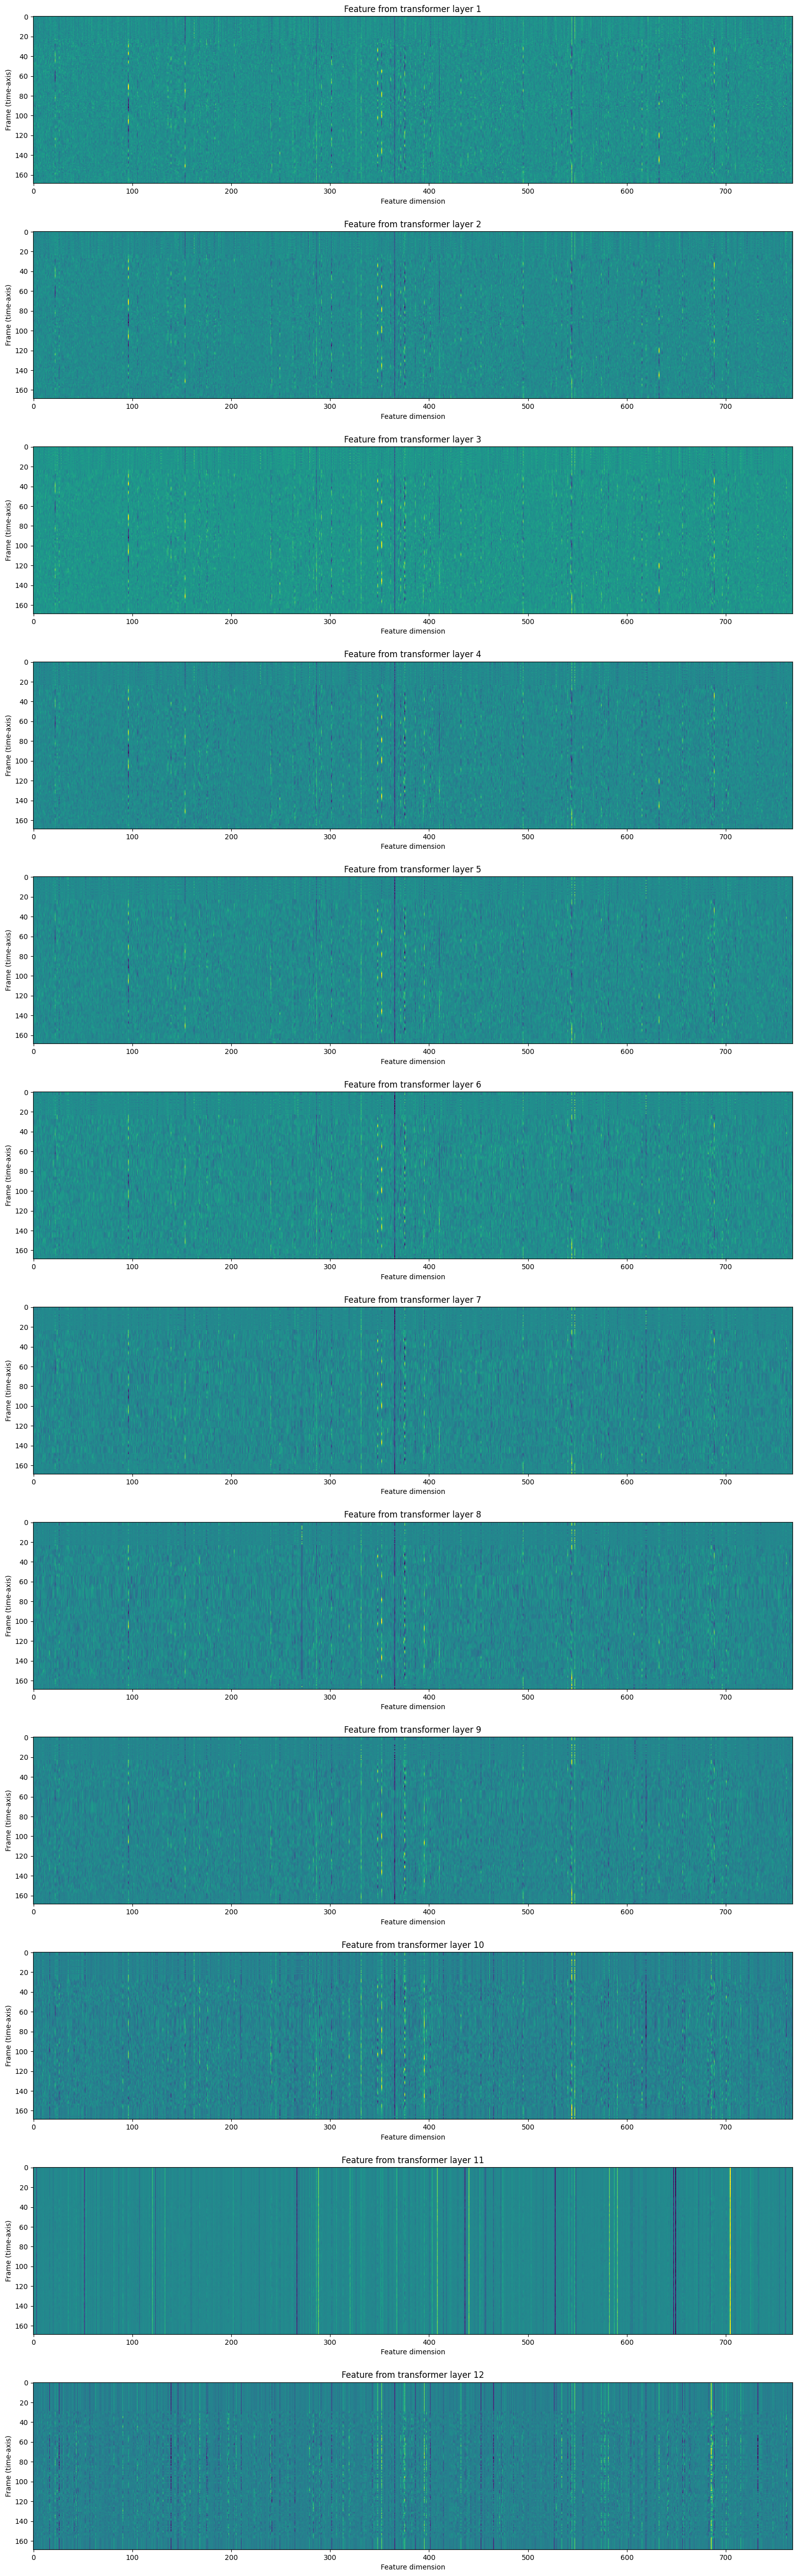

In [24]:
######################################################################
# Las características devueltas son una lista de tensores.
# Cada tensor es la salida de una capa del Transformer.
#
######################################################################

#crea gráficos para visualizar las características (features) extraídas por cada capa   Wav2Vec 2.0.
#Así puedes observar cómo se representan numéricamente las señales de audio dentro de la red neuronal.

# Crea una figura con una fila de gráficos por cada elemento
# de la lista features, uno por cada capa .
# figsize define el ancho y la altura total de la figura.
fig, ax = plt.subplots(len(features), 1, figsize=(16, 4.3 * len(features)))
# Recorre las características extraídas de cada capa.
for i, feats in enumerate(features):
    # Convierte las características del primer audio del lote
    # a la CPU para poder representarlas con Matplotlib.
    # imshow muestra la matriz como una imagen de colores.
    ax[i].imshow(feats[0].cpu(), interpolation="nearest")

    # Coloca un título indicando el número de capa Transformer.
    ax[i].set_title(f"Feature from transformer layer {i+1}")
    # Etiqueta el eje horizontal: dimensión de las características.
    ax[i].set_xlabel("Feature dimension")
    # Etiqueta el eje vertical: posición temporal o frame.
    ax[i].set_ylabel("Frame (time-axis)")

# Ajusta automáticamente los espacios para evitar que
# los títulos y las etiquetas se superpongan.
fig.tight_layout()



> Estos gráficos representan las características extraídas por las 12 capas del Transformer de Wav2Vec 2.0. En el eje vertical observamos los frames o segmentos temporales del audio y en el eje horizontal las dimensiones de las características. Los colores representan los distintos valores de activación. Podemos observar cómo las representaciones se van transformando a medida que avanzan por las capas del modelo.





> Estos gráficos no muestran directamente las palabras que se están pronunciando. Muestran las representaciones internas que el modelo utiliza para realizar el reconocimiento de voz.

In [25]:
######################################################################
# Clasificación de características
# --------------------------------
#
# Una vez extraídas las características acústicas, el siguiente paso
# consiste en clasificarlas en un conjunto de categorías.
#
# El modelo Wav2Vec2 proporciona un método para realizar la extracción
# de características y la clasificación en un solo paso.
#
######################################################################

#Este código pasa el audio por el modelo Wav2Vec 2.0 para obtener las predicciones acústicas que se utilizarán para reconocer el habla

# Desactiva el cálculo de gradientes porque vamos a utilizar
# el modelo para realizar inferencia, no para entrenarlo.
with torch.inference_mode():
     # Pasa la señal de audio por el modelo Wav2Vec 2.0.
    # emission contiene las puntuaciones de las etiquetas
    # que el modelo predice para cada instante temporal.
    emission, _ = model(waveform) #genera las puntuaciones.

#Imaginá que una persona dice en inglés: “HELLO”.
#El modelo Wav2Vec 2.0 no recibe directamente la palabra escrita. Recibe el audio y va analizando pequeños fragmentos de tiempo
#para predecir qué letra o símbolo corresponde a cada fragmento.

#¿Qué contiene emission?
# emission es una tabla de puntuaciones que genera la red neuronal. Por ejemplo, imaginemos que obtiene estos resultados simplificados:

#Instante del audio	H	    E	    L	    O
#1	              0.80	0.10	0.05	0.05
#2	              0.10	0.75	0.10	0.05
#3	              0.05	0.10	0.80	0.05
#4	              0.05	0.10	0.75	0.10
#5	              0.05	0.05	0.10	0.80
#Cada fila representa un instante del audio y cada columna una etiqueta posible. La puntuación más alta indica cuál considera más probable el modelo para ese instante.

#¿Cómo se convierte en texto?
#El decodificador selecciona la etiqueta con mayor puntuación en cada instante y procesa la secuencia para formar el texto reconocido.


Class labels: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


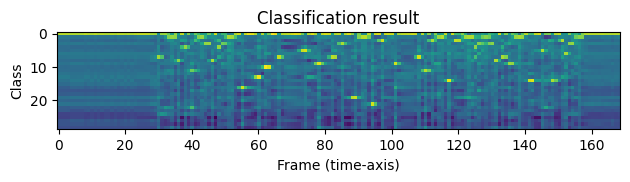

In [26]:
######################################################################
# La salida tiene la forma de logits. No está expresada en forma
# de probabilidades.
#
# Vamos a visualizarlo.
#
######################################################################

# Este código genera un gráfico con los resultados de clasificación de Wav2Vec 2.0.
# Permite observar qué puntuación le asigna el modelo a cada letra o símbolo en los distintos momentos del audio.


# Seleccionar el primer audio y graficar sus resultados.
# emission[0] selecciona los resultados del primer audio.
# .cpu() mueve los datos a la CPU para poder graficarlos.
# .T transpone la matriz, intercambiando filas y columnas.
# plt.imshow(): representa los valores mediante una imagen de colores.
#  interpolation="nearest": muestra los valores sin suavizar la imagen.
plt.imshow(emission[0].cpu().T, interpolation="nearest")
# Establece el título del gráfico.
plt.title("Classification result")
# Etiqueta el eje horizontal: frames o pasos temporales.
plt.xlabel("Frame (time-axis)")
# Etiqueta el eje vertical: clases o símbolos posibles.
plt.ylabel("Class")
# Ajusta los espacios del gráfico para que no se superpongan
# los títulos y las etiquetas.
plt.tight_layout()

# Muestra las etiquetas que corresponden a las clases
# que puede predecir el modelo.
print("Class labels:", bundle.get_labels())

# El gráfico muestra las puntuaciones de clasificación que genera Wav2Vec 2.0 para cada instante del audio.

## Eje horizontal: Frame (time-axis)

Representa los pasos temporales de la predicción. Tu gráfico tiene aproximadamente 167 frames.



## Eje vertical: Class

Representa las 29 etiquetas posibles: el símbolo -, el separador |, las letras de la A a la Z y el apóstrofo.



## Colores

Representan las puntuaciones de cada clase en cada frame. Las zonas más brillantes indican valores más altos según la escala de colores.

##¿Qué significan las zonas brillantes?
En el gráfico se observa una franja brillante cerca de la clase 0 y varios puntos destacados entre los frames 30 y 150.

Esto indica que el modelo asigna puntuaciones elevadas a ciertas clases en determinados instantes. La franja superior podría corresponder al símbolo -, que es el símbolo blank utilizado por CTC.

Sin embargo, para identificar con precisión qué letra predice cada punto, necesitamos consultar los valores numéricos de emission. El gráfico por sí solo no permite leer una transcripción completa

In [27]:
######################################################################
# Podemos observar que hay indicios claros de ciertas etiquetas
# a lo largo de la línea de tiempo.
#
######################################################################

######################################################################
# Generación de transcripciones
# -----------------------------
#
# A partir de la secuencia de probabilidades de las etiquetas,
# ahora queremos generar transcripciones.
# El proceso de generar hipótesis suele llamarse "decodificación".
#
# La decodificación es más compleja que una clasificación simple,
# porque la predicción en un instante determinado puede verse
# afectada por las observaciones que la rodean.
#
# Por ejemplo, consideremos palabras como ``night`` (noche) y
# ``knight`` (caballero). Aunque sus distribuciones de probabilidad
# previas sean diferentes (en conversaciones habituales, ``night``
# aparecería con mucha más frecuencia que ``knight``), para generar
# correctamente transcripciones que contengan ``knight``, como
# ``a knight with a sword`` (un caballero con una espada), el proceso
# de decodificación debe posponer la decisión final hasta disponer
# de suficiente contexto.
#
# Se han propuesto muchas técnicas de decodificación que requieren
# recursos externos, como diccionarios de palabras y modelos
# de lenguaje.
#
# En este tutorial, por simplicidad, utilizaremos la decodificación
# voraz (greedy decoding), que no depende de esos componentes externos
# y simplemente selecciona la mejor hipótesis en cada instante.
# Por lo tanto, no se utiliza información contextual y solo se puede
# generar una transcripción.
#
# Comenzaremos definiendo el algoritmo de decodificación voraz.
#
######################################################################


#Esta clase implementa un decodificador CTC Greedy (Connectionist Temporal Classification).
#Su función es convertir las predicciones numéricas de Wav2Vec 2.0 en una cadena de texto, seleccionando la etiqueta con mayor puntuación en cada instante del audio.


"""
Esta clase implementa un decodificador CTC Greedy.
Recibe las predicciones de Wav2Vec 2.0, selecciona en cada instante la letra o símbolo con mayor puntuación,
elimina las repeticiones consecutivas y los símbolos blank.
Finalmente, convierte los índices en letras y las concatena para obtener la transcripción del audio.

"""

# El símbolo blank es un símbolo especial de CTC que representa la ausencia de un carácter
# en un instante determinado.
# Permite separar letras repetidas y ayuda a construir correctamente la transcripción del audio.
class GreedyCTCDecoder(torch.nn.Module): # Define un decodificador CTC Greedy como un módulo de PyTorch.
    # Inicializa el decodificador con las etiquetas del modelo
    # y el índice correspondiente al símbolo blank.
    def __init__(self, labels, blank=0):
        super().__init__() #inicializa el módulo de PyTorch.
        self.labels = labels #contiene las letras y símbolos que puede reconocer el modelo.
        self.blank = blank #indica el índice del símbolo vacío (blank)

    #Recibe las puntuaciones que genera el modelo para cada letra o símbolo y devuelve una cadena de texto
    def forward(self, emission: torch.Tensor) -> str:
       # Selecciona, en cada instante, la etiqueta con mayor puntuación.
        indices = torch.argmax(emission, dim=-1)
        # Elimina las etiquetas repetidas consecutivas.
        #Por ejemplo:
        #H H H O O L A A
        #Se convierte en:
        #H O L A
        indices = torch.unique_consecutive(indices, dim=-1)
        # Elimina los símbolos vacíos (blank), que no representan una letra.
        indices = [i for i in indices if i != self.blank]
        # Convierte los índices restantes en sus letras correspondientes y las une para formar la transcripción.
        return "".join([self.labels[i] for i in indices])


In [28]:
######################################################################
# Ahora creamos el objeto decodificador y decodificamos la transcripción.
#######################################################################

"""
Primero creamos el decodificador CTC Greedy utilizando las etiquetas del modelo.
Después le pasamos las puntuaciones generadas por Wav2Vec 2.0 para obtener la transcripción del primer audio.
Finalmente, mostramos el texto reconocido y reproducimos nuevamente el audio original para comprobar el resultado.
"""

# Crea el decodificador CTC Greedy utilizando las etiquetas
# que puede reconocer el modelo Wav2Vec 2.0.
#bundle.get_labels() obtiene las letras y símbolos que puede reconocer Wav2Vec 2.0.
# decoder guarda el decodificador que utilizará esas etiquetas para construir el texto.

decoder = GreedyCTCDecoder(labels=bundle.get_labels())

# Decodifica las predicciones del primer audio del lote.
# emission[0] contiene las puntuaciones que generó el modelo para el primer audio.
# decoder() procesa esas puntuaciones.
# Selecciona las letras más probables. Elimina repeticiones consecutivas y símbolos blank. Une las letras para formar el texto.
transcript = decoder(emission[0]) #utiliza esas puntuaciones para construir la transcripción.


######################################################################
# Vamos a comprobar el resultado y escuchar nuevamente el audio.
#
######################################################################
# Muestra la transcripción obtenida.
print(transcript)
IPython.display.Audio(SPEECH_FILE)

I|HAD|THAT|CURIOSITY|BESIDE|ME|AT|THIS|MOMENT|


In [29]:
######################################################################
# El modelo ASR se ajusta mediante una función de pérdida llamada
# Clasificación Temporal Conexionista (Connectionist Temporal
# Classification, CTC).
#
# La explicación detallada de la función de pérdida CTC se encuentra
# aquí: <https://distill.pub/2017/ctc/>.
#
# En CTC, el símbolo en blanco (ϵ) es un símbolo especial que
# representa una repetición del símbolo anterior.
# Durante la decodificación, estos símbolos simplemente se ignoran.
#
######################################################################

# Conclusión
# ----------
#
# En este tutorial, vimos cómo utilizar
# :py:class:`~torchaudio.pipelines.Wav2Vec2ASRBundle` para realizar
# la extracción de características acústicas y el reconocimiento
# de voz.
#
# Crear el modelo y obtener las emisiones requiere tan solo
# dos líneas de código.
#
# ::
#
#    model = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H.get_model()
#    emission = model(waveforms, ...)
#
######################################################################


## Conclusión

En esta actividad se realizó la réplica del tutorial de reconocimiento automático del habla (*Automatic Speech Recognition, ASR*) utilizando la arquitectura Wav2Vec 2.0 y la biblioteca Torchaudio de PyTorch.

Durante el desarrollo se cargó un modelo preentrenado, `WAV2VEC2_ASR_BASE_960H`, que permite reconocer voz en inglés. Se preparó el archivo de audio mediante su carga y adaptación de la frecuencia de muestreo a 16.000 Hz, requerida por el modelo.

Posteriormente, se extrajeron las características acústicas mediante las capas Transformer y se visualizaron sus representaciones para comprender cómo la red neuronal transforma la señal de audio. También se obtuvieron las puntuaciones de clasificación (*emissions*) para cada frame temporal y se implementó un decodificador CTC Greedy para convertir las predicciones en una secuencia de texto.

Esta experiencia permitió comprender las principales etapas del reconocimiento de voz: preparación del audio, extracción de características, clasificación de etiquetas y decodificación de las predicciones.

Finalmente, se comprobó cómo es posible reutilizar un modelo preentrenado para realizar inferencia sin entrenar una red neuronal desde cero. Este procedimiento aprovecha los conocimientos adquiridos durante el entrenamiento previo del modelo y constituye un ejemplo de uso de modelos preentrenados relacionado con el aprendizaje por transferencia (*Transfer Learning*).

##Referencias bibliográficas

* PyTorch. Speech Command Classification with torchaudio. Tutorial utilizado como referencia para la implementación del entrenamiento, la evaluación, el optimizador Adam y el ajuste de la tasa de aprendizaje.
https://docs.pytorch.org/tutorials/intermediate/speech_command_classification_with_torchaudio_tutorial.html


* PyTorch. Datasets and DataLoaders. Documentación sobre la carga y organización de datos para el entrenamiento de modelos.
https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html

* PyTorch. StepLR. Documentación oficial sobre la reducción programada de la tasa de aprendizaje.
https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html